In [28]:
# dependencies

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('dark_background')

In [29]:
df = pd.read_csv('data_science_job.csv')

In [30]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0


In [31]:
# lets see missing values

df.isnull().sum()

enrollee_id                  0
city                         0
city_development_index     479
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
training_hours             766
target                       0
dtype: int64

In [32]:
# to check the perecentage of missing values:

df.isnull().mean()*100

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

In [33]:
# as we can see there are fow col with significant data missing ,

# general thumb hand rule is we apply CCA when there is 5% or less data missing in col ,

# and when sometime tere is lots of missing data in a col we remove the entire column , like 98 or 99% missing data

In [34]:
df.shape

(19158, 13)

In [35]:
rm_col = [var for var in df.columns if df[var].isnull().mean() < 0.05 and df[var].isnull().mean()>0]

rm_col

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [36]:
df[rm_col].sample(5)

,city_development_index,enrolled_university,education_level,experience,training_hours
9712,0.624,Full time course,Graduate,0.0,22.0
10215,NaN,Full time course,Graduate,0.0,26.0
5200,0.920,no_enrollment,Graduate,13.0,12.0
10091,0.698,Full time course,Graduate,1.0,34.0
2490,0.689,no_enrollment,Graduate,5.0,11.0


In [37]:
# now lets see if we remove these col how many data will be left

len(df[rm_col].dropna()) / len(df)

0.8968577095730244

In [38]:
# 89% data will be left

In [39]:
new_df = df[rm_col].dropna()

In [40]:
new_df.shape, df.shape

((17182, 5), (19158, 13))

# now all we need to do is the check how much change has occured to the distribution of data 

## for numerical cols -- plot kde to see the change
## for categorical cols -- compare the ration of each value_count with respect to the og_data and new_data

In [62]:
import seaborn as sns


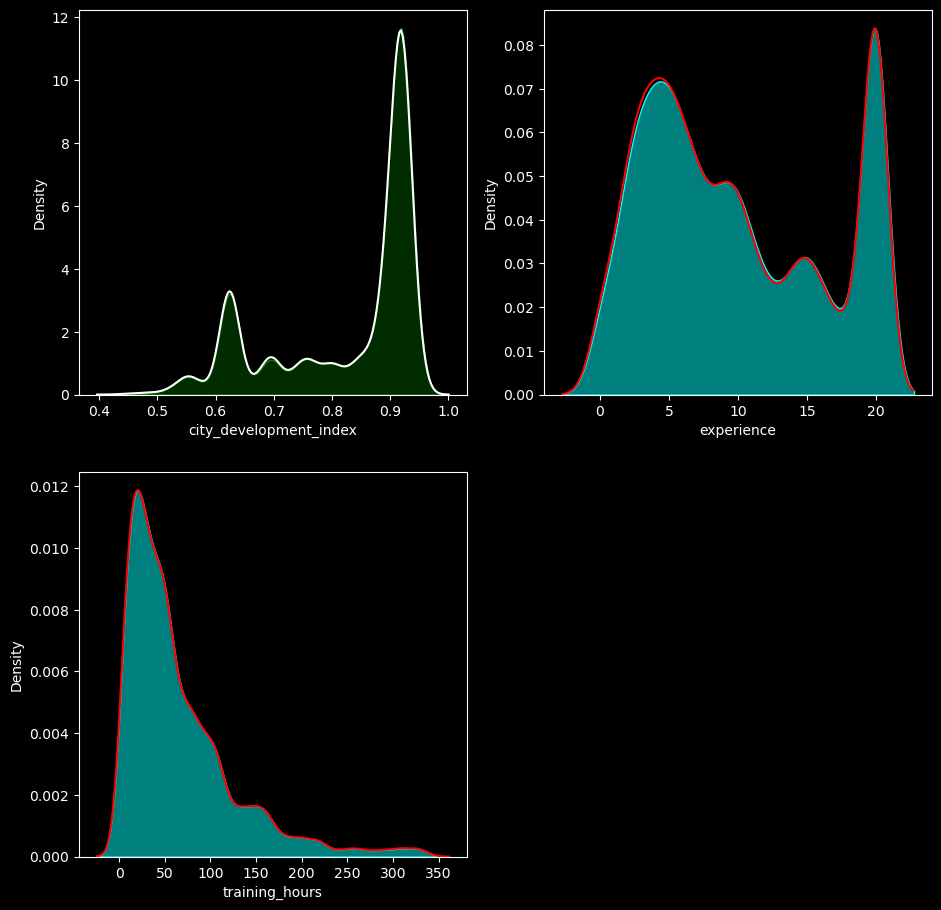

In [75]:
# lets see first num cols


plt.figure(figsize=(11,11))


# graph1 
plt.subplot(2,2,1)
sns.kdeplot(new_df['city_development_index'], fill=True,color='green',alpha=0.35)
sns.kdeplot(df['city_development_index'],color='white',alpha=1)


# graph2
plt.subplot(2,2,2)
sns.kdeplot(new_df['experience'], fill=True,color='cyan',alpha=0.5)
sns.kdeplot(df['experience'],color='red',alpha=1)


# graph3
plt.subplot(2,2,3)
sns.kdeplot(new_df['training_hours'], fill=True,color='cyan',alpha=0.5)
sns.kdeplot(df['training_hours'],color='red',alpha=1)

plt.show()

### as we can see that all are alomost same 

In [79]:
df[['city_development_index','experience','training_hours']].skew()

city_development_index   -0.998721
experience                0.338826
training_hours            1.824589
dtype: float64

In [80]:
new_df[['city_development_index','experience','training_hours']].skew()

city_development_index   -1.033541
experience                0.318035
training_hours            1.827387
dtype: float64

## NOW lets take care of cat col

In [83]:
new_df.sample()

,city_development_index,enrolled_university,education_level,experience,training_hours
14818,0.92,no_enrollment,Graduate,20.0,26.0


In [84]:
new_df['enrolled_university'].value_counts()

enrolled_university
no_enrollment       12632
Full time course     3449
Part time course     1101
Name: count, dtype: int64

In [85]:
new_df['education_level'].value_counts()

education_level
Graduate          10650
Masters            4022
High School        1845
Phd                 380
Primary School      285
Name: count, dtype: int64

In [86]:
temp = pd.concat([
            # percentage of observations per category, original data
            df['enrolled_university'].value_counts() / len(df),

            # percentage of observations per category, cca data
            new_df['enrolled_university'].value_counts() / len(new_df)
        ],
        axis=1)

# add column names
temp.columns = ['original', 'cca']

temp

,original,cca
enrolled_university,,
no_enrollment,0.721213,0.735188
Full time course,0.196106,0.200733
Part time course,0.062533,0.064079


In [87]:
temp = pd.concat([
            # percentage of observations per category, original data
            df['education_level'].value_counts() / len(df),

            # percentage of observations per category, cca data
            new_df['education_level'].value_counts() / len(new_df)
        ],
        axis=1)

# add column names
temp.columns = ['original', 'cca']

temp

,original,cca
education_level,,
Graduate,0.605387,0.619835
Masters,0.227633,0.234082
High School,0.105282,0.107380
Phd,0.021610,0.022116
Primary School,0.016077,0.016587


In [88]:
# Done✅